# Bounds from Observed Outcomes

## Bounding effects with missing counterfactuals

For unit $i$, let $Y_i(1)$ be the outcome under treatment and let $Y_i(0)$ be the outcome under control. The individual treatment effect is

$$
\tau_i=Y_i(1)-Y_i(0).
$$

The symbol $\tau_i$ is the change for unit $i$ between its two potential outcomes. Only one potential outcome is observed because the treatment indicator $D_i$ takes either zero or one. The observed outcome is

$$
Y_i=D_iY_i(1)+(1-D_i)Y_i(0).
$$

Here, $Y_i$ is the recorded outcome and $D_i=1$ denotes treatment. This equality is the consistency relation used by the calculation. It does not state that treated and control units are exchangeable.

### Worst-Case Bounds

Suppose every potential outcome lies in the supplied interval $[L,U]$. For a treated unit, the missing control outcome can take any value in that interval. Its effect therefore lies between $Y_i-U$ and $Y_i-L$. For a control unit, the missing treated outcome gives the interval from $L-Y_i$ to $U-Y_i$. Averaging these unit ranges gives

$$
\underline\tau=\frac{1}{n}\sum_{i=1}^{n}\left[D_i(Y_i-U)+(1-D_i)(L-Y_i)\right],
$$

and

$$
\overline\tau=\frac{1}{n}\sum_{i=1}^{n}\left[D_i(Y_i-L)+(1-D_i)(U-Y_i)\right].
$$

The quantities $\underline\tau$ and $\overline\tau$ are the lower and upper limits for the empirical average treatment effect. The number of units is $n$, while $L$ and $U$ are supplied outcome limits. These are identification limits for the observed finite population, not sampling confidence limits.

#### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_partial_identification");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis: manski_ate_bounds
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
using .BookSensitivityStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter05_random_inputs"),"sensitivity")
captions=Dict("manski_notation"=>"Notation for bounded-outcome identification.","manski_assumptions"=>"Assumptions and limits of the bounded-outcome calculation.","manski_exact_enumeration"=>"Extreme missing-potential-outcome enumeration for three units.","manski_exact_summary"=>"Exact comparison of released and enumerated limits.","manski_boundary_cases"=>"Boundary cases accepted by the released calculation.","manski_invalid_input_checks"=>"Invalid-input checks for the bounded-outcome calculation.","manski_outcome_range_sensitivity"=>"Identification limits as the supplied upper outcome limit changes.","mpdta_bound_provenance"=>"Provenance of the public panel used for the bounded-outcome example.","mpdta_binary_group_summary"=>"Public county outcomes by the fixed group indicator.","mpdta_binary_bounds"=>"Worst-case limits for the public binary county outcome.","manski_treatment_share_sweep"=>"Location of the binary-outcome limits as the treatment fraction changes.","manski_section_summary"=>"Summary of the bounded-outcome calculations.","sensitivity_notation"=>"Notation for regression sensitivity analysis.","sensitivity_generated_design"=>"Declared parameters of the controlled omitted-variable calculation.","sensitivity_generated_models"=>"Reduced, full, and sensitivity-adjusted exposure estimates.","sensitivity_generated_strengths"=>"Conditional strengths in the controlled calculation.","sensitivity_recovery_checks"=>"Recovery and zero-strength checks.","sensitivity_identity_cases"=>"Selected sensitivity calculations with supplied strengths.","mpdta_regression_models"=>"Descriptive public county regressions.","mpdta_regression_summary"=>"Public county sample used in the descriptive sensitivity calculation.","mpdta_observed_covariate_benchmarks"=>"Exact observed-covariate sensitivity benchmarks.","mpdta_observed_covariate_benchmarks_book"=>"Observed-covariate sensitivity benchmarks used in the chapter.","sensitivity_robustness_values"=>"Robustness values for the controlled and public calculations.","regions_notation"=>"Notation for identification and sensitivity regions.","regions_assumption_ledger"=>"Assumption ledger for the chapter calculations.","regions_public_bound_decomposition"=>"Treated and control contributions to the public binary-outcome limits.","regions_continuous_outcome_padding"=>"Effect limits under alternative supplied ranges for the public continuous outcome.","regions_width_surface_corners"=>"Corner cases from the outcome-range surface.","regions_sensitivity_sign_counts"=>"Grid counts on each side of the zero-estimate boundary.","regions_zero_estimate_frontier_points"=>"Selected finite points on the zero-estimate frontier.","regions_integration_checks"=>"Checks linking the identification and sensitivity calculations.","regions_section_summary"=>"How to interpret the chapter's identification and sensitivity regions.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim5-"*replace(name,"_"=>"-"))
    return nothing
end;


#### Returns and observed prices

In [1]:
function generated_sensitivity()
    values=normal_block(store,"generated")
    x,z,noise_d,noise_y=eachcol(values)
    d=.8 .*z+.3 .*x+noise_d
    y=2 .*d+1.4 .*z+x+noise_y
    reduced=sensitivity_ols(y,d,x)
    full=sensitivity_ols(y,d,x,z)
    d_reduced=sensitivity_ols(d,x)
    d_full=sensitivity_ols(d,x,z)
    return (;x,z,d,y,reduced,full,r2d=sensitivity_partial_r2(d_reduced,d_full),r2y=sensitivity_partial_r2(reduced,full))
end
notation = frame(["Symbol","Description"],[["Y_i(1)","Potential outcome for unit i under treatment"],["Y_i(0)","Potential outcome for unit i under control"],["D_i","Binary treatment indicator for unit i"],["Y_i","Observed outcome for unit i"],["L","Supplied lower outcome limit"],["U","Supplied upper outcome limit"],["tau_i","Individual treatment effect"],["underline tau, overline tau","Lower and upper empirical average-effect limits"]])
table(notation,"manski_notation")
assumptions = frame(["Requirement","Role"],[["Consistency","Connects the observed outcome to the potential outcome under the received treatment"],["Binary treatment","Separates treated and control potential outcomes"],["Supplied outcome interval","Restricts every observed and missing potential outcome to L through U"],["Treatment exchangeability","Not required by the worst-case calculation"],["Sampling model","Not supplied; the result is not a confidence interval"]])
table(assumptions,"manski_assumptions")
observed=[.2,.8,.5]
treatment=[1,0,1]
records=[]
for first_missing in (0.,1.),second_missing in (0.,1.),third_missing in (0.,1.)
    missing_values=[first_missing,second_missing,third_missing]
    y1=ifelse.(treatment.==1,observed,missing_values)
    y0=ifelse.(treatment.==1,missing_values,observed)
    effects=y1-y0
    push!(records,(first_missing,second_missing,third_missing,(effects[1]+effects[2]+effects[3])/3))
end
enumeration=frame(["Missing value for unit 1","Missing value for unit 2","Missing value for unit 3","Average treatment effect"],records)
bounds=manski_ate_bounds(observed,treatment;lower=0,upper=1);


Row,Symbol,Description
,String,String
1,Y_i(1),Potential outcome for unit i under treatment
2,Y_i(0),Potential outcome for unit i under control
3,D_i,Binary treatment indicator for unit i
4,Y_i,Observed outcome for unit i
5,L,Supplied lower outcome limit
6,U,Supplied upper outcome limit
7,tau_i,Individual treatment effect
8,"underline tau, overline tau",Lower and upper empirical average-effect limits


Row,Requirement,Role
,String,String
1,Consistency,Connects the observed outcome to the potential outcome under the received treatment
2,Binary treatment,Separates treated and control potential outcomes
3,Supplied outcome interval,Restricts every observed and missing potential outcome to L through U
4,Treatment exchangeability,Not required by the worst-case calculation
5,Sampling model,Not supplied; the result is not a confidence interval


#### All Extreme Counterfactual Completions

Row,Missing value for unit 1,Missing value for unit 2,Missing value for unit 3,Average treatment effect
,Float64,Float64,Float64,Float64
1,0.0,0.0,0.0,-0.0333333
2,0.0,0.0,1.0,-0.366667
3,0.0,1.0,0.0,0.3
4,0.0,1.0,1.0,-0.0333333
5,1.0,0.0,0.0,-0.366667
6,1.0,0.0,1.0,-0.7
7,1.0,1.0,0.0,-0.0333333
8,1.0,1.0,1.0,-0.366667


Row,Quantity,Value
,String,Real
1,Released lower limit,-0.7
2,Enumerated minimum,-0.7
3,Released upper limit,0.3
4,Enumerated maximum,0.3
5,Treatment fraction,0.666667
6,Unit count,3


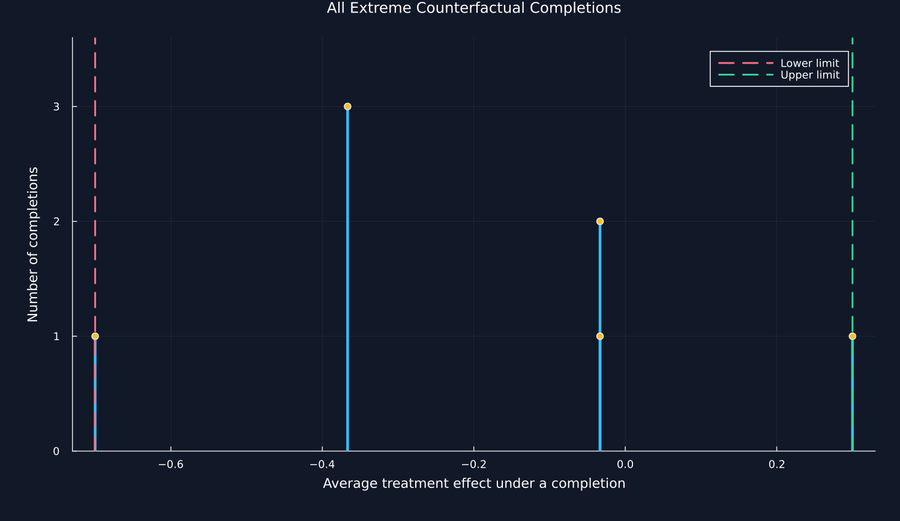

In [1]:
@assert isapprox(bounds.lower,minimum(enumeration[:,4]))
@assert isapprox(bounds.upper,maximum(enumeration[:,4]))
table(enumeration,"manski_exact_enumeration")
exact_summary=frame(["Quantity","Value"],[("Released lower limit",bounds.lower),("Enumerated minimum",minimum(enumeration[:,4])),("Released upper limit",bounds.upper),("Enumerated maximum",maximum(enumeration[:,4])),("Treatment fraction",bounds.treated_fraction),("Unit count",bounds.sample_count)])
table(exact_summary,"manski_exact_summary")
effects=sort(unique(enumeration[:,4]))
enum_plot=frame(["Average treatment effect","Completions"],[(effect,count(==(effect),enumeration[:,4])) for effect in effects])
save_data(enum_plot,paths,"manski_exact_distribution")
figure=plot(;size=(1000,580),xlabel="Average treatment effect under a completion",ylabel="Number of completions",title="All Extreme Counterfactual Completions",ylims=(0,maximum(enum_plot[:,2])*1.2))
for row in eachrow(enum_plot)
    plot!(figure,[row[1],row[1]],[0,row[2]];color=palette.cyan,linewidth=3,label="")
end
scatter!(figure,enum_plot[:,1],enum_plot[:,2];color=palette.amber,label="")
vline!(figure,[bounds.lower];color=palette.rose,linestyle=:dash,label="Lower limit")
vline!(figure,[bounds.upper];color=palette.green,linestyle=:dash,label="Upper limit")
save_figure(figure,paths,"manski_exact_distribution")


## How boundary cases change the width of the effect region

Every unit-level interval has width $U-L$. The empirical average interval therefore has width

$$
\overline\tau-\underline\tau=U-L.
$$

This equality explains why a wider supplied outcome range directly widens the identification region. The treated fraction and observed group means move the location of the region, but without another assumption they cannot reduce its worst-case width.

Row,Case,Lower limit,Upper limit,Treatment fraction,Unit count
,String,Float64,Float64,Float64,Int64
1,All treated,0.0,1.0,1.0,2
2,All control,0.0,1.0,0.0,2
3,Constant outcome range,0.0,0.0,0.5,2
4,Mixed binary outcomes,-0.5,0.5,0.5,4


Row,Check,Rejected
,String,String
1,Observed outcome above upper limit,Pass
2,Treatment value outside zero and one,Pass
3,Reversed outcome limits,Pass
4,Mismatched array lengths,Pass


Row,Upper outcome limit,Lower effect limit,Upper effect limit,Region width
,Float64,Float64,Float64,Float64
1,0.8,-0.566667,0.233333,0.8
2,0.9,-0.633333,0.266667,0.9
3,1.0,-0.7,0.3,1.0
4,1.1,-0.766667,0.333333,1.1
5,1.2,-0.833333,0.366667,1.2
6,1.3,-0.9,0.4,1.3
7,1.4,-0.966667,0.433333,1.4
8,1.5,-1.03333,0.466667,1.5
9,1.6,-1.1,0.5,1.6


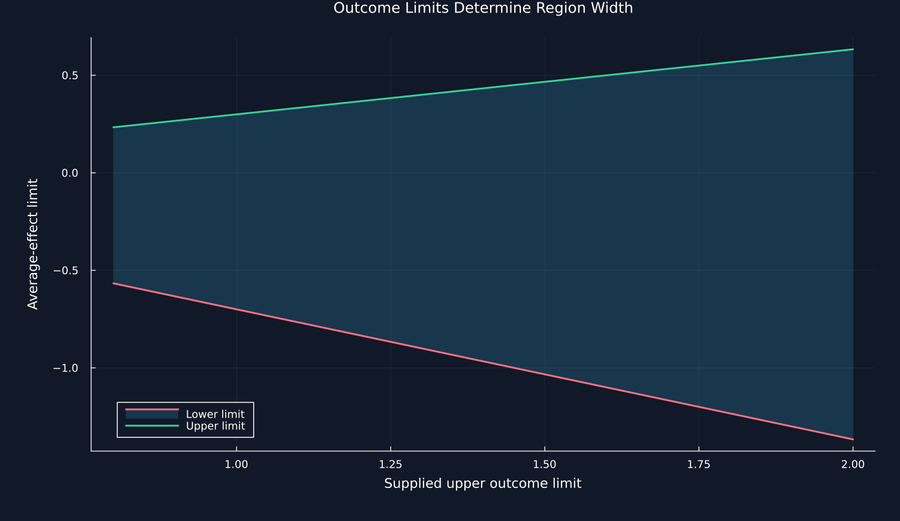

In [2]:
boundary_records=[]
for (name,y,d,lower,upper) in [("All treated",[1,1],[1,1],0,1),("All control",[0,0],[0,0],0,1),("Constant outcome range",[2,2],[0,1],2,2),("Mixed binary outcomes",[0,1,1,0],[0,0,1,1],0,1)]
    result=manski_ate_bounds(y,d;lower,upper)
    push!(boundary_records,(name,result.lower,result.upper,result.treated_fraction,result.sample_count))
end
boundary_frame=frame(["Case","Lower limit","Upper limit","Treatment fraction","Unit count"],boundary_records)
table(boundary_frame,"manski_boundary_cases")
invalid_records=[]
for (name,arguments) in [("Observed outcome above upper limit",([2],[1],0,1)),("Treatment value outside zero and one",([.5],[2],0,1)),("Reversed outcome limits",([.5],[1],1,0)),("Mismatched array lengths",([.5,.4],[1],0,1))]
    passed=try
        manski_ate_bounds(arguments[1],arguments[2];lower=arguments[3],upper=arguments[4])
        false
    catch error
        error isa ArgumentError
    end
    push!(invalid_records,(name,passed))
end
invalid_frame=frame(["Check","Rejected"],invalid_records)
@assert all(invalid_frame.Rejected)
table(invalid_frame,"manski_invalid_input_checks")
upper_grid=collect(range(.8,2.;length=13))
range_frame=frame(["Upper outcome limit","Lower effect limit","Upper effect limit","Region width"],[(upper,result.lower,result.upper,result.upper-result.lower) for upper in upper_grid for result in (manski_ate_bounds(observed,treatment;lower=0,upper),)])
table(range_frame,"manski_outcome_range_sensitivity")
save_data(range_frame,paths,"manski_outcome_range_sensitivity")
figure=plot(upper_grid,range_frame[:,2];fillrange=range_frame[:,3],fillcolor=palette.cyan,fillalpha=.18,color=palette.rose,label="Lower limit",xlabel="Supplied upper outcome limit",ylabel="Average-effect limit",title="Outcome Limits Determine Region Width",size=(1000,580))
plot!(figure,upper_grid,range_frame[:,3];color=palette.green,label="Upper limit")
save_figure(figure,paths,"manski_outcome_range_sensitivity")


## A Public County-Panel Calculation

For each county, define a binary outcome that equals one when log employment rose from 2006 to 2007. The teaching calculation uses the fixed group indicator in the public panel as $D_i$. With $L=0$ and $U=1$, the natural outcome range is known. The resulting interval states what the observed binary outcomes and consistency alone imply for this empirical set of counties. It does not identify a minimum-wage effect because exchangeability is not assumed.

Row,Item,Value
,String,Any
1,Public source,Callaway and Sant'Anna county panel
2,Local file,data/public/callaway_santanna/mpdta.csv
3,File bytes,124867
4,Panel rows,2500
5,Counties,500
6,First year,2003
7,Last year,2007
8,Download during execution,None


Row,Group,Counties,Employment increase rate,Mean employment change
,String,Int64,Float64,Float64
1,Never-treated group,309,0.585761,0.00650252
2,Treated cohort group,191,0.486911,-0.0320352


Row,Quantity,Value
,String,Real
1,Lower effect limit,-0.558
2,Upper effect limit,0.442
3,Region width,1.0
4,Treatment fraction,0.382
5,County count,500


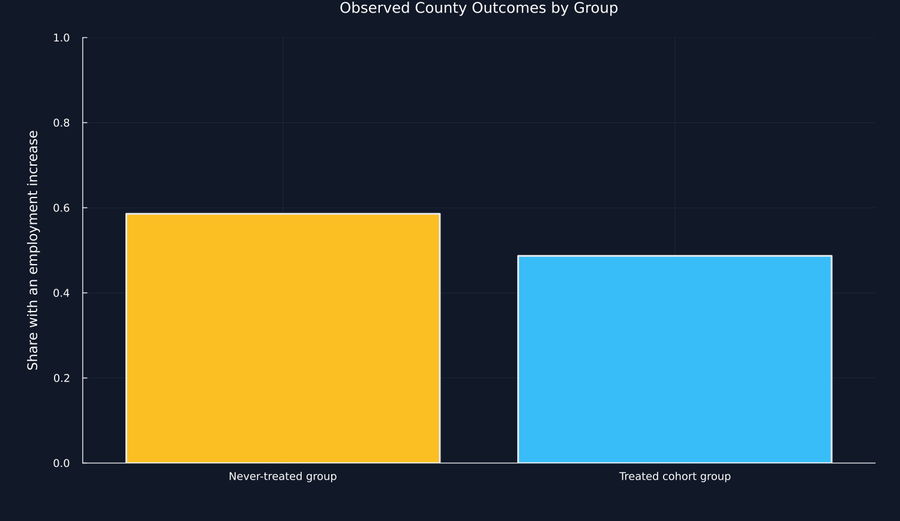

Row,Treatment fraction,Lower effect limit,Upper effect limit
,Float64,Float64,Float64
1,0.05,-0.582127,0.417873
2,0.1,-0.578493,0.421507
3,0.15,-0.57486,0.42514
4,0.2,-0.571226,0.428774
5,0.25,-0.567593,0.432407
6,0.3,-0.563959,0.436041
7,0.35,-0.560325,0.439675
8,0.4,-0.556692,0.443308
9,0.45,-0.553058,0.446942


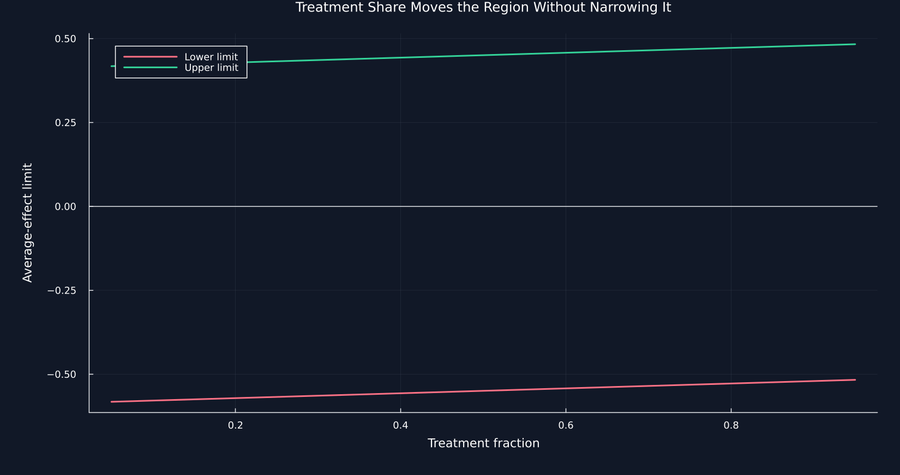

Row,Result,Value
,String,String
1,Exact enumeration,Released limits equal the minimum and maximum across all extreme completions
2,Boundary populations,All-treated and all-control inputs are accepted
3,Region width,Equals the supplied outcome range U minus L
4,Public example,Identification region only; no exchangeability or sampling claim


In [3]:
raw,counties=sensitivity_counties()
data_file=joinpath(book_root(),"data","public","callaway_santanna","mpdta.csv")
provenance=frame(["Item","Value"],[("Public source","Callaway and Sant'Anna county panel"),("Local file","data/public/callaway_santanna/mpdta.csv"),("File bytes",filesize(data_file)),("Panel rows",nrow(raw)),("Counties",length(unique(raw.countyreal))),("First year",minimum(raw.year)),("Last year",maximum(raw.year)),("Download during execution","None")])
table(provenance,"mpdta_bound_provenance")
group_summary=frame(["Group","Counties","Employment increase rate","Mean employment change"],[(group==0 ? "Never-treated group" : "Treated cohort group",count(==(group),counties[:,2]),mean(counties[counties[:,2].==group,8]),mean(counties[counties[:,2].==group,7])) for group in (0,1)])
table(group_summary,"mpdta_binary_group_summary")
public_bounds=manski_ate_bounds(counties[:,8],counties[:,2];lower=0,upper=1)
public_bound_frame=frame(["Quantity","Value"],[("Lower effect limit",public_bounds.lower),("Upper effect limit",public_bounds.upper),("Region width",public_bounds.upper-public_bounds.lower),("Treatment fraction",public_bounds.treated_fraction),("County count",public_bounds.sample_count)])
table(public_bound_frame,"mpdta_binary_bounds")
rate_data=group_summary[:,["Group","Employment increase rate"]]
save_data(rate_data,paths,"mpdta_binary_rates")
figure=bar(rate_data[:,1],rate_data[:,2];color=[palette.amber,palette.cyan],ylims=(0,1),ylabel="Share with an employment increase",title="Observed County Outcomes by Group",legend=false,size=(1000,580))
save_figure(figure,paths,"mpdta_binary_rates")
treated_mean=mean(counties[counties[:,2].==1,8])
control_mean=mean(counties[counties[:,2].==0,8])
share_frame=frame(["Treatment fraction","Lower effect limit","Upper effect limit"],[(share,share*(treated_mean-1)+(1-share)*(0-control_mean),share*treated_mean+(1-share)*(1-control_mean)) for share in range(.05,.95;length=19)])
table(share_frame,"manski_treatment_share_sweep")
save_data(share_frame,paths,"manski_treatment_share_sweep")
figure=plot(share_frame[:,1],share_frame[:,2];color=palette.rose,label="Lower limit",xlabel="Treatment fraction",ylabel="Average-effect limit",title="Treatment Share Moves the Region Without Narrowing It",size=(1100,580))
plot!(figure,share_frame[:,1],share_frame[:,3];color=palette.green,label="Upper limit")
hline!(figure,[0.];color=palette.text,linewidth=1,label="")
save_figure(figure,paths,"manski_treatment_share_sweep")
section_summary = frame(["Result","Value"],[["Exact enumeration","Released limits equal the minimum and maximum across all extreme completions"],["Boundary populations","All-treated and all-control inputs are accepted"],["Region width","Equals the supplied outcome range U minus L"],["Public example","Identification region only; no exchangeability or sampling claim"]])
table(section_summary,"manski_section_summary")
@assert isapprox(public_bounds.upper-public_bounds.lower,1.)
